# Dataset B — RealMLP v1: số liệu và bằng chứng nghiên cứu

## Tóm tắt

Sổ tay này là nơi tra cứu nhanh cấu hình, số liệu nghiên cứu và bằng chứng. Bộ chạy và bộ kiểm tra nằm trong các mô-đun dự án; sổ tay không sao chép mã thực thi.

Bằng chứng hiện có: mô hình đã khớp trên 205.310 dòng Train trong 51 vòng GPU; dự đoán Validation gồm 43.995 dòng đã được kiểm tra độc lập; ngưỡng được khóa tại 0,771. Đánh giá RQ1 trên 43.996 dòng Test đã hoàn tất; bảng chỉ số và hiệu chuẩn ở Mục 11. Kết quả thuộc khóa đặc trưng tạm thời v0.2.

Biến an toàn `EXECUTE_RMLP07` mặc định là `False`; khi giữ nguyên, sổ tay không khởi chạy huấn luyện.

## 1. Thiết lập đường dẫn và chế độ chạy

Cell dưới chỉ thiết lập đường dẫn, import thư viện đọc artifact và khóa chế độ review. Các cell kết quả chỉ đọc hiện vật đã công bố; không gọi runner huấn luyện hoặc dự đoán.


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import SVG, display


def tim_project_root(start: Path) -> Path:
    """Tìm project root từ thư mục làm việc hiện tại."""
    resolved = start.resolve()
    for candidate in (resolved, *resolved.parents):
        if (candidate / "src").is_dir() and (candidate / "config").is_dir():
            return candidate
    raise RuntimeError("Không tìm thấy project root chứa src/ và config/.")


PROJECT_ROOT = tim_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

EXECUTE_RMLP07 = False
DEVICE_INDEX = 0
REALMLP_ROOT = PROJECT_ROOT / "artifacts" / "dataset_b" / "realmlp_v1"
RECOVERY_EVIDENCE_ROOT = PROJECT_ROOT / "artifacts" / "dataset_b" / "realmlp_v1_recovery_20260928"
RECOVERY_VALIDATION_DIR = RECOVERY_EVIDENCE_ROOT / "validation"
RECOVERY_TEST_DIR = RECOVERY_EVIDENCE_ROOT / "test"
RUNTIME_DIR = REALMLP_ROOT / "runtime"
PILOT_RUN_DIR = REALMLP_ROOT / "pilot_run"
CV_ROOT = REALMLP_ROOT / "cv"
FULL_TRAIN_DIR = REALMLP_ROOT / "full_train"

display(pd.DataFrame([
    {
        "project_root": str(PROJECT_ROOT),
        "python_executable": sys.executable,
        "execute_rmlp07": EXECUTE_RMLP07,
        "full_train_exists": FULL_TRAIN_DIR.exists(),
        "recovery_validation_exists": RECOVERY_VALIDATION_DIR.exists(),
        "recovery_test_exists": RECOVERY_TEST_DIR.exists(),
    }
]))


,project_root,python_executable,execute_rmlp07,full_train_exists,recovery_validation_exists,recovery_test_exists
0,D:\Proj\DAP\DAP391m_GR12,D:\Proj\DAP\DAP391m_GR12\.venv-realmlp-gpu\Scr...,False,True,True,True


## 2. Kiểm tra kernel GPU

Cell này fail-fast nếu notebook không chạy bằng `.venv-realmlp-gpu`. Nó cũng so sánh môi trường hiện tại với bằng chứng RMLP-04. Đây chỉ là GPU preflight; không có model fit.


In [2]:
from src.dataset_b.runtime.realmlp_smoke import (
    _validate_runtime_artifacts,
    collect_realmlp_runtime_environment,
)

GPU_ENV_ROOT = (PROJECT_ROOT / ".venv-realmlp-gpu").resolve()
ACTIVE_ENV_ROOT = Path(sys.executable).resolve().parent.parent
if ACTIVE_ENV_ROOT != GPU_ENV_ROOT:
    raise RuntimeError(
        "Sai kernel. Hãy chọn kernel realmlp_gpu chạy từ "
        f"{GPU_ENV_ROOT} trước khi tiếp tục. Hiện tại: {sys.executable}"
    )

_validate_runtime_artifacts(RUNTIME_DIR)
runtime_manifest = json.loads(
    (RUNTIME_DIR / "runtime_manifest.json").read_text(encoding="utf-8")
)
current_environment = collect_realmlp_runtime_environment(DEVICE_INDEX)
recorded_environment = runtime_manifest["environment"]
identity_fields = (
    "python_executable",
    "packages",
    "device_index",
    "cuda_build_version",
    "gpu_name",
)
identity_mismatches = [
    field
    for field in identity_fields
    if current_environment.get(field) != recorded_environment.get(field)
]
if not current_environment.get("ready_for_smoke") or identity_mismatches:
    raise RuntimeError(
        "GPU preflight không đạt. "
        f"errors={current_environment.get('errors')}, "
        f"identity_mismatches={identity_mismatches}"
    )

display(pd.DataFrame([
    {
        "status": "PASS",
        "gpu": current_environment["gpu_name"],
        "cuda": current_environment["cuda_build_version"],
        "batch_size": runtime_manifest["selected_batch_size"],
        "python": current_environment["python_executable"],
    }
]))


W0928 15:08:31.333000 18320 .venv-realmlp-gpu\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


D:\Proj\DAP\DAP391m_GR12\.venv-realmlp-gpu\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,status,gpu,cuda,batch_size,python
0,PASS,NVIDIA GeForce RTX 5050 Laptop GPU,13.0,256,D:\Proj\DAP\DAP391m_GR12\.venv-realmlp-gpu\Scr...


## 3. Xác minh RMLP-04, RMLP-05 và RMLP-06B

Các checker hiện hữu được gọi trực tiếp. RMLP-06B checker chỉ nạp phân vùng Train để đối chiếu thành viên và OOF; phần Validation được trình bày riêng ở Mục 10. Mục 11 chỉ đọc dự đoán Test và chỉ số đã công bố để tra cứu, không gọi lại mô hình.


In [3]:
from src.dataset_b.runtime.realmlp_cv import validate_realmlp_production_cv
from src.dataset_b.runtime.realmlp_pilot_run import validate_realmlp_pilot_run

pilot_manifest = validate_realmlp_pilot_run(PILOT_RUN_DIR)
cv_manifest = validate_realmlp_production_cv(CV_ROOT)
decision = json.loads(
    (PILOT_RUN_DIR / "decision.json").read_text(encoding="utf-8")
)
cv_results = json.loads(
    (CV_ROOT / "summary" / "cv_results.json").read_text(encoding="utf-8")
)

if decision.get("status") != "LOCKED" or decision.get("decision") != "FIXED_EPOCH":
    raise RuntimeError("RMLP-05 decision không phải LOCKED/FIXED_EPOCH.")
if decision["full_train_refit_policy"].get("n_epochs") != 51:
    raise RuntimeError("RMLP-05 không khóa full-Train ở 51 epoch.")
if cv_results.get("rows") != 205_310 or cv_results.get("unique_record_ids") != 205_310:
    raise RuntimeError("RMLP-06B OOF cardinality không đúng 205.310 rows.")

display(pd.DataFrame([
    {"gate": "RMLP-04", "status": runtime_manifest["status"], "evidence": str(RUNTIME_DIR)},
    {"gate": "RMLP-05", "status": pilot_manifest["status"], "evidence": str(PILOT_RUN_DIR)},
    {"gate": "RMLP-06B", "status": cv_manifest["status"], "evidence": str(CV_ROOT)},
]))


,gate,status,evidence
0,RMLP-04,PASS,D:\Proj\DAP\DAP391m_GR12\artifacts\dataset_b\r...
1,RMLP-05,PASS,D:\Proj\DAP\DAP391m_GR12\artifacts\dataset_b\r...
2,RMLP-06B,PASS,D:\Proj\DAP\DAP391m_GR12\artifacts\dataset_b\r...


## 4. CV metrics và artifact lineage

Bảng fold dùng exact stored values từ RMLP-06B. Bảng hash dùng summary manifest đã được checker xác minh. Không tính hoặc suy diễn thêm metric mới.


In [4]:
fold_rows = []
for fold_number in range(1, 6):
    fold_dir = CV_ROOT / f"fold_{fold_number:02d}"
    fold_result = json.loads(
        (fold_dir / "fold_result.json").read_text(encoding="utf-8")
    )
    fold_rows.append({
        "fold": fold_number,
        "train_rows": fold_result["data_boundary"]["fold_train_rows"],
        "fold_validation_rows": fold_result["data_boundary"]["fold_validation_rows"],
        "epochs": fold_result["history"]["observed_records"],
        "roc_auc": fold_result["metrics"]["roc_auc"],
        "category_support_failures": fold_result["data_boundary"]["category_support_failures"],
    })

fold_table = pd.DataFrame(fold_rows)
display(fold_table.style.format({"roc_auc": "{:.10f}"}))


,fold,train_rows,fold_validation_rows,epochs,roc_auc,category_support_failures
0,1,164248,41062,51,0.8585869041,0
1,2,164248,41062,51,0.8579231709,0
2,3,164248,41062,51,0.8614359511,0
3,4,164248,41062,51,0.8556209377,0
4,5,164248,41062,51,0.8606521374,0


In [5]:
summary_metrics = pd.DataFrame([
    {
        "oof_rows": cv_results["rows"],
        "unique_record_ids": cv_results["unique_record_ids"],
        "mean_fold_roc_auc": cv_results["metrics"]["mean_roc_auc"],
        "population_std_roc_auc": cv_results["metrics"]["std_roc_auc"],
        "oof_roc_auc": cv_results["metrics"]["oof_roc_auc"],
    }
])
display(summary_metrics.style.format({
    "mean_fold_roc_auc": "{:.10f}",
    "population_std_roc_auc": "{:.10f}",
    "oof_roc_auc": "{:.10f}",
}))

hash_table = pd.DataFrame(
    [
        {"artifact": relative_path, "sha256": sha256_value}
        for relative_path, sha256_value in sorted(cv_manifest["artifact_sha256"].items())
    ]
)
display(hash_table)


,oof_rows,unique_record_ids,mean_fold_roc_auc,population_std_roc_auc,oof_roc_auc
0,205310,205310,0.8588438202,0.0020634789,0.8588220609


,artifact,sha256
0,cv_results.json,0d03f90c3c3e8feb7959697ee7795fef786a0fb1d5b950...
1,oof_predictions.csv,766540354037be0e7e4d4794957887220938971b39a640...


## 5. Xem trước cấu hình RMLP-07

Đây là preview từ locked decision và runtime evidence. Notebook không cho phép chỉnh epoch, early stopping, validation channel hoặc output contract.


In [6]:
from src.dataset_b.runtime.realmlp_full_train import (
    EXPECTED_TRAIN_ROWS,
    FIXED_EPOCHS,
)

refit_policy = decision["full_train_refit_policy"]
configuration_preview = pd.DataFrame([
    {
        "source_partition": "train",
        "expected_train_rows": EXPECTED_TRAIN_ROWS,
        "fit_membership": refit_policy["fit_membership"],
        "epochs": FIXED_EPOCHS,
        "batch_size": runtime_manifest["selected_batch_size"],
        "inner_stop_set": refit_policy["inner_stop_set"],
        "use_early_stopping": refit_policy["use_early_stopping"],
        "use_best_epoch": False,
        "project_validation_accessed": False,
        "project_test_accessed": False,
        "output_dir": str(FULL_TRAIN_DIR),
    }
])
display(configuration_preview)


,source_partition,expected_train_rows,fit_membership,epochs,batch_size,inner_stop_set,use_early_stopping,use_best_epoch,project_validation_accessed,project_test_accessed,output_dir
0,train,205310,all_immutable_train_rows,51,256,none,False,False,False,False,D:\Proj\DAP\DAP391m_GR12\artifacts\dataset_b\r...


## 6. Ô huấn luyện có công tắc an toàn

Ô này chỉ khởi chạy huấn luyện khi `EXECUTE_RMLP07=True`. Khi công tắc là `False`, ô bỏ qua huấn luyện và chỉ ghi nhận điều đó; việc kiểm tra gói kết quả đã công bố nằm ở ô kế tiếp. Không chạy đồng thời bộ chạy dòng lệnh và ô này cho cùng một lượt huấn luyện.


In [7]:
from src.dataset_b.runtime.realmlp_full_train import run_realmlp_full_train

if EXECUTE_RMLP07:
    full_train_manifest = run_realmlp_full_train(
        FULL_TRAIN_DIR,
        pilot_run_dir=PILOT_RUN_DIR,
        cv_root=CV_ROOT,
        runtime_dir=RUNTIME_DIR,
        device_index=DEVICE_INDEX,
    )
    display(pd.DataFrame([full_train_manifest]))
else:
    display(pd.DataFrame([{
        "task": "Lượt huấn luyện trong sổ tay",
        "status": "ĐÃ BỎ QUA THEO CÔNG TẮC AN TOÀN",
        "reason": "EXECUTE_RMLP07=False; xem gói kết quả đã công bố tại ô kiểm tra bên dưới.",
    }]))


,task,status,reason
0,Lượt huấn luyện trong sổ tay,ĐÃ BỎ QUA THEO CÔNG TẮC AN TOÀN,EXECUTE_RMLP07=False; xem gói kết quả đã công ...


## 7. Kiểm tra gói kết quả đã công bố

Nếu `full_train/` chưa tồn tại, ô ghi rõ chưa có gói kết quả. Nếu đã tồn tại, bộ kiểm tra xác nhận dấu hoàn tất, mã băm, số dòng Train, 51 bản ghi lịch sử, thông tin không dùng Validation và gói mô hình.


In [8]:
from src.dataset_b.runtime.realmlp_full_train import validate_realmlp_full_train

if FULL_TRAIN_DIR.exists():
    validated_full_train_manifest = validate_realmlp_full_train(
        FULL_TRAIN_DIR,
        pilot_run_dir=PILOT_RUN_DIR,
        cv_root=CV_ROOT,
        runtime_dir=RUNTIME_DIR,
    )
    full_train_result = json.loads(
        (FULL_TRAIN_DIR / "full_train_result.json").read_text(encoding="utf-8")
    )
    display(pd.DataFrame([{
        "artifact": "Mô hình khớp trên toàn bộ Train",
        "status": validated_full_train_manifest["status"],
        "train_rows": validated_full_train_manifest["train_rows"],
        "epochs": validated_full_train_manifest["fixed_epochs"],
        "validation_accessed": full_train_result["data_boundary"]["project_validation_accessed"],
        "test_accessed": full_train_result["data_boundary"]["project_test_accessed"],
    }]))
else:
    full_train_result = None
    display(pd.DataFrame([{
        "artifact": "Mô hình khớp trên toàn bộ Train",
        "status": "CHƯA CÓ GÓI KẾT QUẢ",
        "evidence": "Không tìm thấy thư mục full_train/",
    }]))


,artifact,status,train_rows,epochs,validation_accessed,test_accessed
0,Mô hình khớp trên toàn bộ Train,PASS,205310,51,False,False


## 8. Lịch sử huấn luyện và hình minh họa

Ô này hiển thị bảng 51 vòng và hình SVG do bộ chạy tạo từ lịch sử thật. Nếu chưa có tệp lịch sử, ô thông báo thiếu bằng chứng; không tạo dữ liệu hoặc hình giả.


,epoch,train_loss,inner_val_loss,learning_rate,epoch_time_seconds,elapsed_time_seconds,gpu_memory_used_mb,status
0,1,0.478877,None,3.383313e-02,5.006121,5.026842,121.488281,COMPLETED
1,2,0.397886,None,2.995378e-02,4.883863,9.913318,126.214844,COMPLETED
2,3,0.380508,None,2.963257e-03,4.981444,14.900001,126.214844,COMPLETED
3,4,0.370896,None,5.571794e-03,5.049805,19.954819,126.214844,COMPLETED
4,5,0.378205,None,2.673219e-02,5.090199,25.049397,126.214844,COMPLETED
5,6,0.386100,None,3.956992e-02,4.935844,29.986041,126.214844,COMPLETED
6,7,0.387016,None,3.518331e-02,4.556675,34.547386,126.214844,COMPLETED
7,8,0.381391,None,2.059441e-02,4.752189,39.301592,126.214844,COMPLETED
8,9,0.373028,None,6.624716e-03,4.678749,43.982555,126.214844,COMPLETED
9,10,0.366926,None,1.823482e-04,4.874010,48.861724,126.214844,COMPLETED


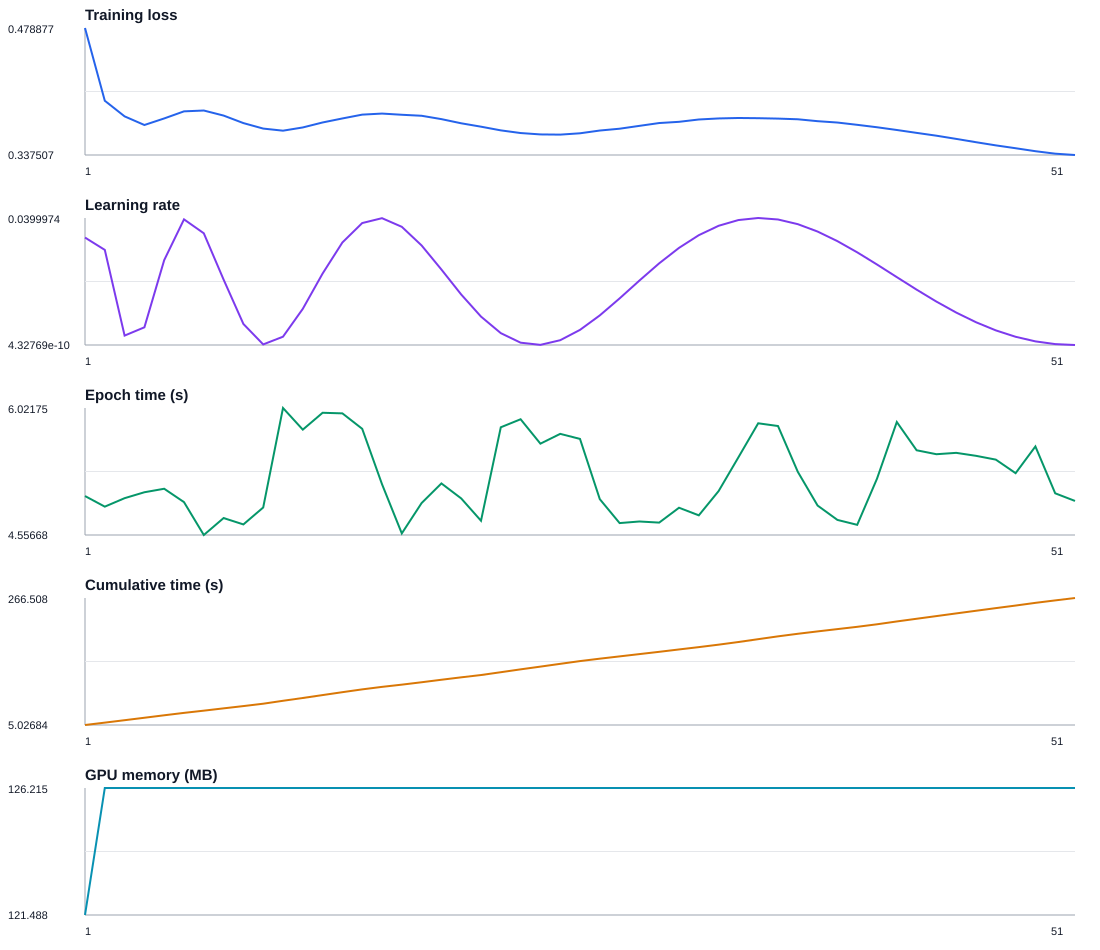

In [9]:
history_path = FULL_TRAIN_DIR / "training_history.json"
history_svg_path = FULL_TRAIN_DIR / "plots" / "full_train_history.svg"
if history_path.exists() and history_svg_path.exists():
    history_payload = json.loads(history_path.read_text(encoding="utf-8"))
    history_table = pd.DataFrame(history_payload["records"])
    selected_columns = [
        "epoch",
        "train_loss",
        "inner_val_loss",
        "learning_rate",
        "epoch_time_seconds",
        "elapsed_time_seconds",
        "gpu_memory_used_mb",
        "status",
    ]
    display(history_table[selected_columns])
    display(SVG(filename=str(history_svg_path)))
else:
    display(pd.DataFrame([{
        "task": "RMLP-07D history",
        "status": "NOT EXECUTED",
        "reason": "Chưa có training_history.json và full_train_history.svg.",
    }]))


## 9. Phạm vi bằng chứng

Sổ tay trình bày kết quả CV, huấn luyện toàn bộ Train, dự đoán Validation, ngưỡng khóa và đánh giá RQ1 trên Test. Mục 11 đọc số liệu trực tiếp từ gói kết quả RMLP-09 đã kiểm tra.


In [10]:
if full_train_result is None:
    artifact_evidence = pd.DataFrame([{"gói kết quả": "CHƯA CÓ", "vị trí": str(FULL_TRAIN_DIR)}])
else:
    artifact_evidence = pd.DataFrame([{
        "gói kết quả": validated_full_train_manifest["status"],
        "số dòng Train": validated_full_train_manifest["train_rows"],
        "số vòng cố định": validated_full_train_manifest["fixed_epochs"],
        "số bản ghi lịch sử": full_train_result["history"]["observed_records"],
        "đã đọc Validation": full_train_result["data_boundary"]["project_validation_accessed"],
        "đã đọc Test": full_train_result["data_boundary"]["project_test_accessed"],
    }])
display(artifact_evidence)


,gói kết quả,số dòng Train,số vòng cố định,số bản ghi lịch sử,đã đọc Validation,đã đọc Test
0,PASS,205310,51,51,False,False


## 10. Dự đoán Validation và chọn ngưỡng

Bảng và hình dưới đây đọc trực tiếp hiện vật dự đoán cùng bảng ứng viên ngưỡng đã công bố. Đây là kết quả trên Validation (tập xác thực); chưa phải đánh giá cuối cùng trên Test (tập kiểm tra).

,số dòng Validation,mã bản ghi duy nhất,mã băm dự đoán,trung bình p_approved,trung vị p_approved
0,43995,43995,9997e89f678aa61c0a6af22958af4de5847ec090ac971a...,0.747103,0.87905


,số_dòng,trung_bình,trung_vị,nhỏ_nhất,lớn_nhất
y_approved,,,,,
Thực tế: không duyệt,11181,0.416827,0.365464,1.999748e-12,0.993217
Thực tế: duyệt,32814,0.859641,0.911782,7.346492e-04,0.999168


,ngưỡng khóa,Balanced Accuracy (độ chính xác cân bằng),Recall (độ thu hồi) duyệt,Recall (độ thu hồi) không duyệt,TP duyệt,FN duyệt,TN không duyệt,FP không duyệt,số ngưỡng đồng hạng tối đa
0,0.771,0.782619,0.846072,0.719166,27763,5051,8041,3140,1


,Ngưỡng,Balanced Accuracy (độ chính xác cân bằng),Recall (độ thu hồi) duyệt,Recall (độ thu hồi) không duyệt,Duyệt đúng,Duyệt sai,Từ chối đúng,Từ chối sai
768,0.769,0.782455,0.848784,0.716126,27852,4962,8007,3174
769,0.770,0.782334,0.847291,0.717378,27803,5011,8021,3160
770,0.771,0.782619,0.846072,0.719166,27763,5051,8041,3140
771,0.772,0.782411,0.844761,0.720061,27720,5094,8051,3130
772,0.773,0.782340,0.843725,0.720955,27686,5128,8061,3120


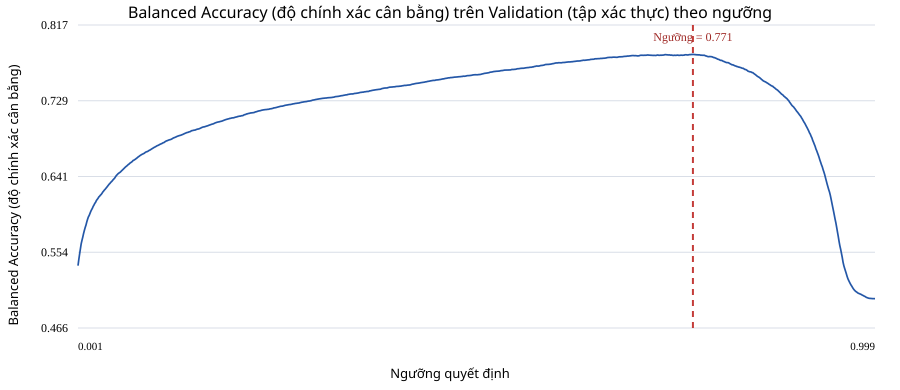

In [11]:
from src.dataset_b.evaluation.realmlp_validation import validate_realmlp_validation

VALIDATION_DIR = RECOVERY_VALIDATION_DIR

if VALIDATION_DIR.exists():
    validation_manifest = validate_realmlp_validation(VALIDATION_DIR)
    validation_result = json.loads((VALIDATION_DIR / "validation_result.json").read_text(encoding="utf-8"))
    validation_predictions = pd.read_csv(VALIDATION_DIR / "validation_predictions.csv")
    display(pd.DataFrame([{
        "số dòng Validation": validation_manifest["rows"],
        "mã bản ghi duy nhất": validation_manifest["unique_record_ids"],
        "mã băm dự đoán": validation_manifest["artifact_sha256"]["validation_predictions.csv"],
        "trung bình p_approved": validation_result["prediction_summary"]["probability_mean"],
        "trung vị p_approved": validation_result["prediction_summary"]["probability_median"],
    }]))
    validation_score_summary = (
        validation_predictions.groupby("y_approved")["p_approved"]
        .agg(
            số_dòng="size",
            trung_bình="mean",
            trung_vị="median",
            nhỏ_nhất="min",
            lớn_nhất="max",
        )
        .rename(index={0: "Thực tế: không duyệt", 1: "Thực tế: duyệt"})
    )
    display(validation_score_summary)
    from src.dataset_b.evaluation.realmlp_validation_threshold import validate_realmlp_validation_threshold
    threshold_manifest = validate_realmlp_validation_threshold(VALIDATION_DIR)
    threshold_dir = VALIDATION_DIR / "threshold_selection"
    threshold_result = json.loads((threshold_dir / "threshold_selection.json").read_text(encoding="utf-8"))
    threshold_candidates = pd.read_csv(threshold_dir / "threshold_candidates.csv")
    display(pd.DataFrame([{
        "ngưỡng khóa": threshold_result["selected_threshold"],
        "Balanced Accuracy (độ chính xác cân bằng)": threshold_result["selected_metrics"]["balanced_accuracy"],
        "Recall (độ thu hồi) duyệt": threshold_result["selected_metrics"]["recall_approved"],
        "Recall (độ thu hồi) không duyệt": threshold_result["selected_metrics"]["recall_denied"],
        "TP duyệt": threshold_result["validation_counts"]["tp_approved"],
        "FN duyệt": threshold_result["validation_counts"]["fn_approved"],
        "TN không duyệt": threshold_result["validation_counts"]["tn_denied"],
        "FP không duyệt": threshold_result["validation_counts"]["fp_denied"],
        "số ngưỡng đồng hạng tối đa": threshold_result["maximizer_count"],
    }]))
    selected_idx = int((threshold_candidates["threshold"] - threshold_result["selected_threshold"]).abs().idxmin())
    display(threshold_candidates.iloc[max(0, selected_idx - 2):selected_idx + 3].rename(columns={
        "threshold": "Ngưỡng",
        "balanced_accuracy": "Balanced Accuracy (độ chính xác cân bằng)",
        "recall_approved": "Recall (độ thu hồi) duyệt",
        "recall_denied": "Recall (độ thu hồi) không duyệt",
        "tp_approved": "Duyệt đúng", "fn_approved": "Duyệt sai",
        "tn_denied": "Từ chối đúng", "fp_denied": "Từ chối sai",
    }))
    width, height = 900, 390
    left, right, top, bottom = 78, 25, 25, 62
    plot_width, plot_height = width - left - right, height - top - bottom
    scores = threshold_candidates["balanced_accuracy"].to_numpy(dtype=float)
    score_min, score_max = float(scores.min()), float(scores.max())
    score_pad = max((score_max - score_min) * 0.12, 0.002)
    y_min, y_max = score_min - score_pad, score_max + score_pad
    x_values = threshold_candidates["threshold"].to_numpy(dtype=float)
    points = [f'{left + (x - 0.001) / 0.998 * plot_width:.2f},{top + (y_max - y) / (y_max - y_min) * plot_height:.2f}' for x, y in zip(x_values, scores, strict=True)]
    selected_x = left + (threshold_result["selected_threshold"] - 0.001) / 0.998 * plot_width
    grid = "".join(f'<line x1="{left}" y1="{top + i * plot_height / 4:.2f}" x2="{width-right}" y2="{top + i * plot_height / 4:.2f}" stroke="#d9dee7"/><text x="{left-10}" y="{top + i * plot_height / 4 + 4:.2f}" text-anchor="end" font-size="12">{y_max - i * (y_max-y_min)/4:.3f}</text>' for i in range(5))
    threshold_svg = f'''<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="white"/><text x="{width/2}" y="18" text-anchor="middle" font-size="16" font-family="sans-serif">Balanced Accuracy (độ chính xác cân bằng) trên Validation (tập xác thực) theo ngưỡng</text>{grid}<polyline points="{' '.join(points)}" fill="none" stroke="#2457a7" stroke-width="1.7"/><line x1="{selected_x:.2f}" y1="{top}" x2="{selected_x:.2f}" y2="{top+plot_height}" stroke="#c43c39" stroke-width="2" stroke-dasharray="6,5"/><text x="{selected_x:.2f}" y="{top+16}" text-anchor="middle" font-size="12" fill="#9f2926">Ngưỡng = {threshold_result["selected_threshold"]:.3f}</text><text x="{width/2}" y="{height-12}" text-anchor="middle" font-size="13" font-family="sans-serif">Ngưỡng quyết định</text><text x="18" y="{height/2}" transform="rotate(-90 18 {height/2})" text-anchor="middle" font-size="13" font-family="sans-serif">Balanced Accuracy (độ chính xác cân bằng)</text><text x="{left}" y="{height-40}" font-size="11">0.001</text><text x="{width-right}" y="{height-40}" text-anchor="end" font-size="11">0.999</text></svg>'''
    display(SVG(threshold_svg))
else:
    display(pd.DataFrame(["Chưa có hiện vật dự đoán Validation."], columns=["Bằng chứng"]))

### Ghi chú sử dụng

Sổ tay này ưu tiên bảng, số liệu và hình có thể truy xuất trực tiếp từ hiện vật. Mục 10 trình bày Validation và ngưỡng khóa; Mục 11 trình bày kết quả Test, khoảng tin cậy bootstrap và hiệu chuẩn. Không thực hiện so sánh ý nghĩa thống kê giữa các mô hình.


## 11. Đánh giá RQ1 trên Test

Bảng dưới đọc kết quả đã công bố trong `artifacts/dataset_b/realmlp_v1_recovery_20260928/test/`. Ngưỡng `0,771` và mô hình được giữ cố định; khoảng tin cậy 95% dùng đúng 1.000 mẫu bootstrap chung. Đây là đánh giá riêng RealMLP trên khóa đặc trưng tạm thời v0.2, không phải kiểm định chênh lệch giữa mô hình.

In [12]:
from src.dataset_b.evaluation.realmlp_test_evaluation import validate_realmlp_test_evaluation

REALMLP_TEST_DIR = RECOVERY_TEST_DIR
realmlp_test_manifest = validate_realmlp_test_evaluation(
    REALMLP_TEST_DIR,
    validation_dir=VALIDATION_DIR,
)
realmlp_test_metrics = json.loads((REALMLP_TEST_DIR / 'rq1_test_metrics.json').read_text(encoding='utf-8'))
metric_labels = {
    'roc_auc_approved': 'ROC-AUC (diện tích dưới đường cong ROC), duyệt',
    'average_precision_denied': 'PR-AUC (diện tích dưới đường Precision–Recall), từ chối',
    'precision_denied': 'Precision (độ chính xác), từ chối',
    'recall_denied': 'Recall (độ thu hồi), từ chối',
    'f1_denied': 'F1 (trung bình điều hòa), từ chối',
    'recall_approved': 'Recall (độ thu hồi), duyệt',
    'balanced_accuracy': 'Balanced Accuracy (độ chính xác cân bằng)',
    'brier_approved': 'Brier score (điểm Brier), duyệt',
    'calibration_intercept': 'Calibration intercept (hệ số chặn hiệu chuẩn)',
    'calibration_slope': 'Calibration slope (độ dốc hiệu chuẩn)',
}
point = realmlp_test_metrics['point_metrics']
intervals = realmlp_test_metrics['confidence_intervals_95_percentile']
metric_rows = []
for key, label in metric_labels.items():
    ci = intervals[key]
    metric_rows.append({'Chỉ số': label, 'Ước lượng': point[key], 'CI 95% (khoảng tin cậy) dưới': ci['lower_2_5'], 'CI 95% (khoảng tin cậy) trên': ci['upper_97_5'], 'Mẫu hợp lệ': ci['valid_replicates'], 'Mẫu lỗi': ci['invalid_replicates']})
display(pd.DataFrame(metric_rows).style.format({'Ước lượng': '{:.6f}', 'CI 95% (khoảng tin cậy) dưới': '{:.6f}', 'CI 95% (khoảng tin cậy) trên': '{:.6f}'}))
display(pd.DataFrame([{'Số hồ sơ Test': realmlp_test_metrics['rows'], 'Ngưỡng khóa': realmlp_test_metrics['threshold'], 'TP duyệt': realmlp_test_metrics['counts']['tp_approved'], 'FN duyệt': realmlp_test_metrics['counts']['fn_approved'], 'TN từ chối': realmlp_test_metrics['counts']['tn_denied'], 'FP từ chối': realmlp_test_metrics['counts']['fp_denied'], 'Thời gian chạy toàn Train (giây)': realmlp_test_metrics['computational_metrics_seconds']['full_train_runner_elapsed'], 'Thời gian suy luận Test gồm tiền xử lý (giây)': realmlp_test_metrics['computational_metrics_seconds']['test_inference_including_preprocessing']}]).style.format(precision=4))

,Chỉ số,Ước lượng,CI 95% (khoảng tin cậy) dưới,CI 95% (khoảng tin cậy) trên,Mẫu hợp lệ,Mẫu lỗi
0,"ROC-AUC (diện tích dưới đường cong ROC), duyệt",0.857922,0.853382,0.862137,1000,0
1,"PR-AUC (diện tích dưới đường Precision–Recall), từ chối",0.775016,0.768830,0.781076,1000,0
2,"Precision (độ chính xác), từ chối",0.610093,0.603506,0.616980,1000,0
3,"Recall (độ thu hồi), từ chối",0.717914,0.709594,0.726500,1000,0
4,"F1 (trung bình điều hòa), từ chối",0.659627,0.653702,0.665904,1000,0
5,"Recall (độ thu hồi), duyệt",0.843669,0.839646,0.847631,1000,0
6,Balanced Accuracy (độ chính xác cân bằng),0.780792,0.776504,0.785334,1000,0
7,"Brier score (điểm Brier), duyệt",0.108538,0.106827,0.110312,1000,0
8,Calibration intercept (hệ số chặn hiệu chuẩn),-0.003730,-0.023451,0.015899,1000,0
9,Calibration slope (độ dốc hiệu chuẩn),0.919476,0.899062,0.940078,1000,0


,Số hồ sơ Test,Ngưỡng khóa,TP duyệt,FN duyệt,TN từ chối,FP từ chối,Thời gian chạy toàn Train (giây),Thời gian suy luận Test gồm tiền xử lý (giây)
0,43996,0.7710,27685,5130,8027,3154,267.8035,2.9529


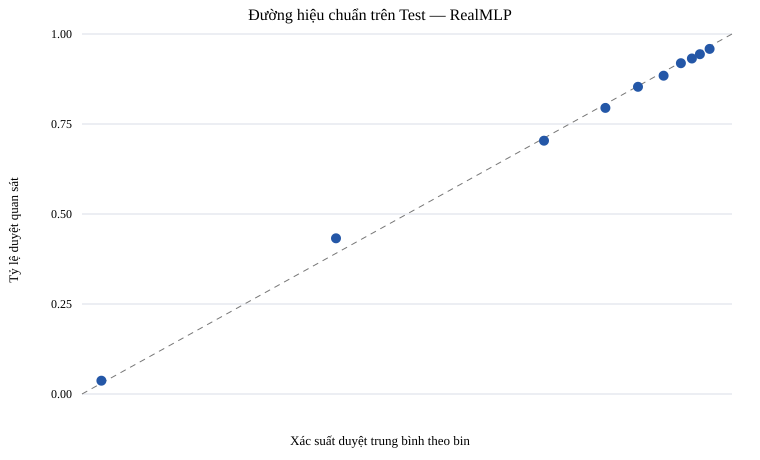

,Bin,Số dòng,Biên dưới,Xác suất duyệt trung bình,Tỷ lệ duyệt quan sát,Biên trên
0,0,4400,0.000000,0.029785,0.036818,0.121266
1,1,4399,0.121266,0.390760,0.432598,0.617867
2,2,4400,0.617867,0.710771,0.703636,0.771610
3,3,4399,0.771610,0.805291,0.794726,0.832970
4,4,4400,0.832970,0.855346,0.853409,0.876973
5,5,4399,0.876973,0.894740,0.884065,0.910159
6,6,4400,0.910159,0.921336,0.918864,0.930953
7,7,4399,0.930953,0.938349,0.932030,0.944978
8,8,4400,0.944978,0.950643,0.943864,0.956084
9,9,4400,0.956084,0.965470,0.958636,0.999189


In [13]:
curve = realmlp_test_metrics['calibration_curve']
width, height, left, right, top, bottom = 760, 460, 82, 28, 34, 66
plot_w, plot_h = width-left-right, height-top-bottom
xy = lambda x, y: (left + x*plot_w, top + (1-y)*plot_h)
grid = ''.join(f'<line x1="{left}" y1="{top+i*plot_h/4:.1f}" x2="{width-right}" y2="{top+i*plot_h/4:.1f}" stroke="#d9dee7"/><text x="{left-10}" y="{top+i*plot_h/4+4:.1f}" text-anchor="end" font-size="12">{1-i/4:.2f}</text>' for i in range(5))
line = f'<line x1="{left}" y1="{top+plot_h}" x2="{left+plot_w}" y2="{top}" stroke="#777" stroke-dasharray="6,5"/>'
points = []
for row in curve:
    x, y = xy(row['mean_p_approved'], row['observed_approval_rate'])
    points.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="5" fill="#2457a7"><title>n={row["count"]}</title></circle>')
calibration_svg = f'''<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="white"/><text x="{width/2}" y="20" text-anchor="middle" font-size="16">Đường hiệu chuẩn trên Test — RealMLP</text>{grid}{line}{''.join(points)}<text x="{width/2}" y="{height-15}" text-anchor="middle" font-size="13">Xác suất duyệt trung bình theo bin</text><text x="18" y="{height/2}" transform="rotate(-90 18 {height/2})" text-anchor="middle" font-size="13">Tỷ lệ duyệt quan sát</text></svg>'''
display(SVG(calibration_svg))
display(pd.DataFrame(curve).rename(columns={'bin': 'Bin', 'lower_edge': 'Biên dưới', 'upper_edge': 'Biên trên', 'count': 'Số dòng', 'mean_p_approved': 'Xác suất duyệt trung bình', 'observed_approval_rate': 'Tỷ lệ duyệt quan sát'}).style.format(precision=6))

## RealMLP v1 — Các quyết định đã khóa và điểm cần lưu ý

| Hạng mục | Quyết định / kết quả | Ý nghĩa và ranh giới |
| --- | --- | --- |
| Cấu hình khớp toàn Train | `FIXED_EPOCH=51`; không early stopping, không best-epoch restore | Khớp trên 205.310 dòng Train; Validation và Test không tham gia fit. |
| CV | 5-fold trên Train; 205.310 dự đoán OOF duy nhất | Mean ROC-AUC 0.858844; độ lệch chuẩn tổng thể 0.002063; OOF ROC-AUC 0.858822. |
| Ngưỡng phân lớp | `0.771`, chọn trên Validation theo Balanced Accuracy | Khi hòa, ưu tiên ngưỡng gần 0.5 nhất rồi ngưỡng thấp hơn; Test không dùng chọn ngưỡng. |
| Đánh giá Test | Mô hình và ngưỡng giữ cố định; 1.000 mẫu bootstrap chung | Chỉ đánh giá RealMLP trên feature lock tạm thời v0.2; chưa phải so sánh cuối giữa các mô hình. |
| Hiệu chuẩn | Calibration slope 0.919476, CI 95% [0.899062; 0.940078] | Mô tả riêng hiệu chuẩn RealMLP trên Test; không suy ra ưu thế so với mô hình khác. |
| Thời lượng | `RealMLP fit đến validated checkpoint elapsed` | Bao gồm lượt chạy đến khi checkpoint được lưu và kiểm tra; không phải thời gian fit thuần và không dùng so sánh trực tiếp giữa mô hình. Không chạy lại Full-Train chỉ để đổi nhãn. |

Không có kiểm định ý nghĩa thống kê cho chênh lệch giữa các mô hình. Các thay đổi về mô hình, đặc trưng hoặc ngưỡng cần được ghi thành phiên bản/run riêng; kết quả này không mở rộng kết luận sang RQ2, RQ3 hoặc khóa đặc trưng cuối.

## RealMLP v1 — Bảng kết quả để đối chiếu

Bản tóm tắt tĩnh từ các artifact RMLP-06B, RMLP-08B và RMLP-09. Kết quả thuộc `temporary_training_lock_v0_2`; các artifact đã lưu giữ độ chính xác đầy đủ.

### Train CV và Validation

| Giai đoạn | Chỉ số | Giá trị |
| --- | --- | ---: |
| Train, 5-fold CV | Mean ROC-AUC | 0.858844 |
| Train, 5-fold CV | Std ROC-AUC (ddof=0) | 0.002063 |
| Train, 5-fold CV | OOF ROC-AUC | 0.858822 |
| Validation | Threshold đã khóa | 0.771 |
| Validation | Balanced Accuracy tại ngưỡng | 0.782619 |
| Validation | Recall Approved | 0.846072 |
| Validation | Recall Denied | 0.719166 |

### Test: point metrics và CI 95%

Test có 43.996 hồ sơ: 32.815 Approved và 11.181 Denied. CI dùng 1.000 mẫu bootstrap chung; cả 10 chỉ số dưới đây có đủ 1.000 mẫu hợp lệ.

| Nhóm | Chỉ số | Ước lượng | CI 95% [2,5%; 97,5%] |
| --- | --- | ---: | ---: |
| Phân biệt | ROC-AUC Approved | 0.857922 | [0.853382; 0.862137] |
| Xếp hạng Denied | Average Precision Denied | 0.775016 | [0.768830; 0.781076] |
| Denied | Precision | 0.610093 | [0.603506; 0.616980] |
| Denied | Recall | 0.717914 | [0.709594; 0.726500] |
| Denied | F1 | 0.659627 | [0.653702; 0.665904] |
| Approved | Recall | 0.843669 | [0.839646; 0.847631] |
| Phân lớp | Balanced Accuracy | 0.780792 | [0.776504; 0.785334] |
| Xác suất | Brier score Approved | 0.108538 | [0.106827; 0.110312] |
| Hiệu chuẩn | Calibration intercept | -0.003730 | [-0.023451; 0.015899] |
| Hiệu chuẩn | Calibration slope | 0.919476 | [0.899062; 0.940078] |

### Ma trận phân lớp và thời lượng

| Nhãn thật | Dự báo Approved | Dự báo Denied | Tổng |
| --- | ---: | ---: | ---: |
| Approved | 27.685 | 5.130 | 32.815 |
| Denied | 3.154 | 8.027 | 11.181 |

- `RealMLP fit đến validated checkpoint elapsed`: 267.8035 giây; gồm thời gian đến khi checkpoint được lưu và kiểm tra, không phải fit thuần. Không dùng chỉ số này để so sánh trực tiếp giữa các mô hình.
- Suy luận Test gồm tiền xử lý: 1.9286 giây. Không tính CI bootstrap cho thời lượng.

### Hiệu chuẩn trên Test

Đường hiệu chuẩn dùng 10 quantile bins, mỗi bin khoảng 4.399–4.400 hồ sơ; hình và bảng chi tiết ở Mục 11. Không có CI cho từng bin.

Nguồn: `artifacts/dataset_b/realmlp_v1/cv/summary/cv_results.json`, `artifacts/dataset_b/realmlp_v1_recovery_20260928/validation/threshold_selection/threshold_selection.json` và `artifacts/dataset_b/realmlp_v1_recovery_20260928/test/rq1_test_metrics.json`.

## RealMLP v1 — Trạng thái tham số baseline

Bảng này ghi cấu hình được khai báo, các giá trị thực tế trong pilot/CV/Full-Train và quyết định rút ra từ pilot. Giá trị cấu hình không đồng nghĩa với tham số đã được tuning tối ưu; kết quả vẫn thuộc feature lock tạm thời v0.2.

### Tham số mô hình đã khai báo và được xác nhận trong Full-Train

| Tham số | Giá trị | Trạng thái / ý nghĩa |
| --- | --- | --- |
| Backend | `pytabkit 1.7.3`, `RealMLP_TD_Classifier` | Đã xác nhận từ cấu hình và checkpoint. |
| `device` | `cuda:0` | Đã resolve trong checkpoint; không cho phép fallback CPU âm thầm. |
| `random_state` | `42` | Đã khai báo. |
| `hidden_sizes` | `[256, 256, 256]` | Ba hidden layers, mỗi lớp 256 units. |
| `act`, `use_parametric_act` | `selu`, `true` | Đã khai báo và lưu trong estimator. |
| `opt` | `adam` | Optimizer đã khai báo. |
| `lr`, `lr_sched` | `0.04`, `coslog4` | Learning rate cơ sở và lịch learning rate; giá trị theo epoch thay đổi theo lịch. |
| `wd`, `wd_sched` | `0.02`, `flat_cos` | Weight decay và lịch điều chỉnh đã khai báo. |
| `p_drop`, `p_drop_sched` | `0.15`, `flat_cos` | Dropout và lịch điều chỉnh đã khai báo. |
| `n_cv`, `n_refit`, `n_repeats`, `n_ens` | `1`, `0`, `1`, `1` | Không phải số fold dự án; CV dự án bên ngoài dùng 5 fold độc lập. |
| `batch_size`, `predict_batch_size` | `256`, `1024` | Batch huấn luyện và dự đoán. |
| `val_metric_name`, `use_ls` | `cross_entropy`, `false` | Metric theo dõi và label smoothing. |
| `verbosity` | `2` | Mức log của backend. |
| Class/sample weighting | `false` / `false` | Không dùng trọng số lớp hay sample weights. |

### Quyết định tham số từ pilot và cấu hình thực tế sau pilot

| Hạng mục | Giá trị đã dùng / quyết định |
| --- | --- |
| Tập pilot | 20% Train = 41.062 dòng; stratified, seed `42` |
| Chia trong pilot | 80% fit = 32.849; 20% inner stop = 8.213; seed `42` |
| Pilot epoch budget | `n_epochs=256`; pilot chạy đủ 256 epoch |
| Pilot early stopping | `use_early_stopping=false`; không dừng sớm, không dùng patience |
| Bằng chứng chọn epoch | Epoch `51` có minimum inner validation cross-entropy `0.375346`; final loss `1.104283`; minimum 16 epoch cuối `0.952134` |
| Quyết định RMLP-05 | `FIXED_EPOCH=51`; lấy mốc từ bằng chứng pilot, không khôi phục best-epoch weights |
| CV và Full-Train | `n_epochs=51`, `use_early_stopping=false`, `use_best_epoch=false`; Full-Train truyền `stop_epoch={cross_entropy: 51}` |
| Validation nội bộ khi fit cuối | Không có: `val_fraction=0`, `X_val=None`, `y_val=None`; không dùng project Validation/Test để chọn epoch |

Việc dùng inner stop trong pilot chỉ để ghi nhận loss sau từng epoch và chọn chính sách số epoch. Vì pilot vẫn chạy hết budget 256 epoch nên đây không phải early stopping. Ở CV và Full-Train, mỗi lượt fit dùng đúng 51 epoch, không có inner stop set.

### Backend controls và trường để mặc định / dẫn xuất

| Tham số | Giá trị ghi nhận | Ghi chú |
| --- | --- | --- |
| `val_fraction` | `0.0` | Backend không tự tách validation; Full-Train checkpoint ghi 0 validation rows. |
| Categorical inputs | 12 cột theo tên; dtype `category` | Dùng native categorical handling của PyTabKit, không external OHE 66 cột. |
| Numeric inputs | `float32`; 16 cột đầu vào native | Theo preprocessing contract RealMLP. |
| `n_threads` | API `None`; checkpoint Full-Train resolve `n_threads_=14` | Phụ thuộc runtime/máy, không phải hyperparameter đã khóa trong YAML. |
| Early-stopping patience | `early_stopping_additive_patience=None`; `early_stopping_multiplicative_patience=None` | Không áp dụng vì early stopping tắt. |
| Constructor fields còn lại trả về `None` | `n_hidden_layers`, `hidden_width`, `tfms`, `max_one_hot_cat_size`, `embedding_size`, `num_emb_type`, `use_plr_embeddings`, `plr_sigma`, `plr_hidden_1`, `plr_hidden_2`, `plr_act_name`, `plr_use_densenet`, `plr_use_cos_bias`, `plr_lr_factor`, `act_lr_factor`, `weight_param`, `weight_init_mode`, `weight_init_gain`, `weight_lr_factor`, `bias_init_mode`, `bias_lr_factor`, `bias_wd_factor`, `add_front_scale`, `scale_lr_factor`, `first_layer_lr_factor`, `block_str`, `first_layer_config`, `last_layer_config`, `middle_layer_config`, `mom`, `mom_sched`, `sq_mom`, `sq_mom_sched`, `opt_eps`, `opt_eps_sched`, `normalize_output`, `clamp_output`, `ls_eps`, `ls_eps_sched`, `early_stopping_additive_patience`, `early_stopping_multiplicative_patience`, `train_metric_name`, `calibration_method`, `sort_quantile_predictions`, `stop_epoch`, `use_best_mean_epoch_for_cv`, `ens_av_before_softmax`, `tmp_folder` | Đầy đủ các field chưa được đặt trong effective `backend_.get_params()` của checkpoint; `None` không khẳng định nội bộ PyTabKit dùng giá trị số/enum nào sau khởi tạo. |
| Fit/internal controls | Constructor `stop_epoch=None`; checkpoint `fit_params_={cross_entropy: 51}`; `history_use_best_epoch=false`; `use_ls=false` | Stop epoch được truyền lúc fit, không phải constructor parameter. |

Các trường `None` nghĩa là project không đặt override cho trường đó; không khẳng định giá trị nội bộ sau khi backend khởi tạo. Bảng effective constructor params được đọc từ `backend_.get_params()` của checkpoint Full-Train. Nếu đổi phiên bản PyTabKit hoặc tạo run mới, cần đọc lại checkpoint/config; không xem các giá trị hiện tại là FINAL_MODEL_PARAMETERS.

Nguồn: `config/dataset_b/realmlp_v1.yaml`, `artifacts/dataset_b/realmlp_v1/pilot/pilot_split_manifest.json`, `artifacts/dataset_b/realmlp_v1/pilot_run/decision.json`, `artifacts/dataset_b/realmlp_v1/full_train/full_train_result.json` và checkpoint `artifacts/dataset_b/realmlp_v1/full_train/checkpoints/fitted_model.pkl`.